# Baseline B0 và vòng lặp agent

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.config import TASK_IDS, TASK_META
from sva.data import canon, load_clean
from sva.eval import accuracy, accuracy_ci, chance, correct, ece, load_predictions, mcnemar, position_rate, reliability
from sva.reasoner import choose_theta, replay

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})

## 1. B0-local trên tập test

In [2]:
b0 = {t: load_predictions("b0_local", t, "test") for t in TASK_IDS}

def summary(preds):
    rows = []
    for t, recs in preds.items():
        if not recs:
            continue
        lo, hi = accuracy_ci(recs)
        pf, gf = position_rate(recs)
        rows.append({"task": t, "paper": TASK_META[t]["paper_id"], "n": len(recs),
                     "accuracy": 100 * accuracy(recs), "CI thấp": 100 * lo, "CI cao": 100 * hi,
                     "ngẫu nhiên": 100 * chance(recs), "ECE": ece(recs),
                     "chọn O1 (%)": 100 * pf, "đáp án O1 (%)": 100 * gf,
                     "s/mẫu": np.mean([r["latency_ms"] for r in recs]) / 1000})
    return pd.DataFrame(rows).set_index("task").round(2)

table = summary(b0)
table

,paper,n,accuracy,CI thấp,CI cao,ngẫu nhiên,ECE,chọn O1 (%),đáp án O1 (%),s/mẫu
task,,,,,,,,,,
q8,Q7,280,45.36,39.63,51.21,25.00,0.05,19.64,21.43,1.35
q9,Q8,280,27.50,22.60,33.01,25.00,0.14,46.79,23.57,3.91
q10,Q9,700,36.14,32.67,39.77,25.00,0.10,18.14,25.29,1.12
q11,Q10,700,31.29,27.96,34.81,25.00,0.08,12.57,25.29,1.14
q13,Q12,490,45.92,41.55,50.35,25.00,0.08,29.80,27.35,1.12
q14,Q13,192,56.77,49.70,63.58,43.32,0.14,43.75,39.06,11.56


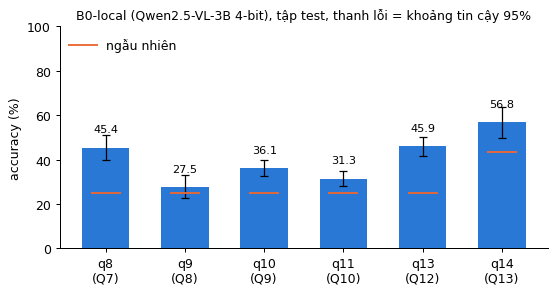

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(table))
err = [table["accuracy"] - table["CI thấp"], table["CI cao"] - table["accuracy"]]
ax.bar(x, table["accuracy"], 0.6, color=BLUE, yerr=err, capsize=3, error_kw={"lw": 1, "color": "#52514e"})
ax.scatter(x, table["ngẫu nhiên"], marker="_", s=600, color=ORANGE, zorder=3, label="ngẫu nhiên")
for i, v in enumerate(table["accuracy"]):
    ax.text(i, v + 7, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x, [f"{t}\n({table.loc[t, 'paper']})" for t in table.index])
ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="upper left")
ax.set_title("B0-local (Qwen2.5-VL-3B 4-bit), tập test, thanh lỗi = khoảng tin cậy 95%", fontsize=10)
plt.show()

### 1.1 Số của paper (khác giao thức)

In [4]:
paper = pd.DataFrame({
    "Qwen2.5-VL-7B (paper)": [56.8, 31.6, 52.2, 51.6, 46.9, 50.7],
    "SoccerAgent MCQ (paper)": [51.1, 35.7, 85.0, 72.9, 46.0, 55.5],
}, index=TASK_IDS)
paper.insert(0, "B0-local 3B (đồ án)", table["accuracy"].round(1))
paper

,B0-local 3B (đồ án),Qwen2.5-VL-7B (paper),SoccerAgent MCQ (paper)
q8,45.4,56.8,51.1
q9,27.5,31.6,35.7
q10,36.1,52.2,85.0
q11,31.3,51.6,72.9
q13,45.9,46.9,46.0
q14,56.8,50.7,55.5


### 1.2 Độ tin cậy

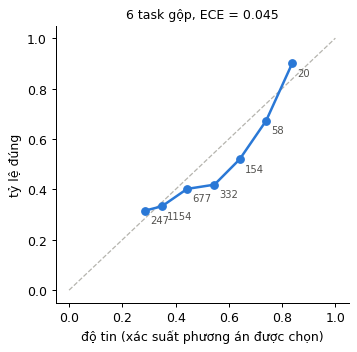

In [5]:
pooled = [r for recs in b0.values() for r in recs]
rel = reliability(pooled)
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
ax.plot([c for c, _, _ in rel], [a for _, a, _ in rel], marker="o", color=BLUE, lw=2)
for c, a, n in rel:
    ax.annotate(str(n), (c, a), textcoords="offset points", xytext=(4, -10), fontsize=8, color="#52514e")
ax.set_xlabel("độ tin (xác suất phương án được chọn)"); ax.set_ylabel("tỷ lệ đúng")
ax.set_title(f"6 task gộp, ECE = {ece(pooled):.3f}", fontsize=10)
plt.show()

### 1.3 Thiên vị vị trí

In [6]:
rows = []
for t, recs in b0.items():
    for name, key in [("dự đoán", "pred"), ("đáp án", "gold")]:
        c = Counter(sorted(r["dist"], key=lambda k: int(k[1:])).index(r[key]) + 1 for r in recs if r.get(key))
        rows.append({"task": t, "loại": name, **{f"vị trí {i}": c[i] / len(recs) for i in range(1, 5)}})
pos = pd.DataFrame(rows).set_index(["task", "loại"]).fillna(0)
(100 * pos).round(1)

vị trí 1  vị trí 2  vị trí 3  vị trí 4
task loại                                           
q8   dự đoán      19.6      36.4      23.6      20.4
     đáp án       21.4      27.9      21.4      29.3
q9   dự đoán      46.8      47.1       3.6       2.5
     đáp án       23.6      27.1      27.1      22.1
q10  dự đoán      18.1      27.6      25.6      28.7
     đáp án       25.3      27.3      25.1      22.3
q11  dự đoán      12.6      43.6      25.0      18.9
     đáp án       25.3      26.9      22.7      25.1
q13  dự đoán      29.8      32.4      18.2      19.6
     đáp án       27.3      24.5      26.5      21.6
q14  dự đoán      43.8      40.6      13.5       2.1
     đáp án       39.1      45.3      11.5       4.2

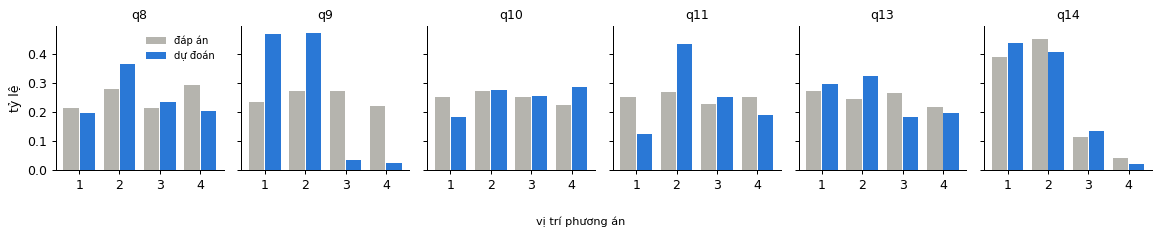

In [7]:
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6), sharey=True)
for ax, t in zip(axes, TASK_IDS):
    p, g = pos.loc[(t, "dự đoán")], pos.loc[(t, "đáp án")]
    k = [c for c in pos.columns if (p[c] + g[c]) > 0]
    xx = np.arange(len(k))
    ax.bar(xx - 0.2, g[k], 0.38, color=GRAY, label="đáp án")
    ax.bar(xx + 0.2, p[k], 0.38, color=BLUE, label="dự đoán")
    ax.set_xticks(xx, [c.split()[-1] for c in k]); ax.set_title(t, fontsize=10)
axes[0].set_ylabel("tỷ lệ"); axes[0].legend(frameon=False, fontsize=8)
fig.supxlabel("vị trí phương án", fontsize=9)
plt.tight_layout(); plt.show()

### 1.4 q14 theo loại câu hỏi

In [8]:
def family(s):
    texts = {canon(t) for t in s.option_texts.values()}
    if texts & {"no card", "yellow card", "red card", "no card or yellow card", "yellow card or red card"}:
        return "mức phạt"
    if texts & {"offence", "no offence", "between"}:
        return "có phạm lỗi không"
    if texts & {"under body", "upper body"}:
        return "vùng cơ thể"
    if texts & {"with contact", "without contact"}:
        return "có va chạm không"
    if texts & {"arms", "shoulder", "use of arms", "use of shoulder"}:
        return "bộ phận dùng"
    if texts <= {"yes", "no", "maybe"}:
        return "có / không"
    return "loại lỗi"

q14 = {s.index: s for s in load_clean("q14")}
fam = pd.DataFrame([{"loại": family(q14[r["index"]]), "đúng": correct(r), "n_opt": r["n_options"]} for r in b0["q14"]])
fam.groupby("loại").agg(n=("đúng", "size"), accuracy=("đúng", "mean"), ngẫu_nhiên=("n_opt", lambda x: (1 / x).mean())).round(3)

,n,accuracy,ngẫu_nhiên
loại,,,
bộ phận dùng,12,0.500,0.333
có / không,72,0.486,0.500
có phạm lỗi không,26,0.846,0.333
có va chạm không,25,1.000,0.500
loại lỗi,15,0.467,0.250
mức phạt,11,0.545,0.250
vùng cơ thể,31,0.258,0.500


## 2. Vòng lặp agent (dev)

In [9]:
# chay voi theta = 1.0 nen moi mau deu di het cac buoc; o day mo phong lai voi theta bat ky
trace = {t: load_predictions("b0_loop_trace", t, "dev") for t in TASK_IDS}
thetas = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.01]
best, _ = choose_theta(trace, thetas)
rows = []
for t, recs in trace.items():
    for th in thetas:
        out = [replay(r, th) for r in recs]
        rows.append({"task": t, "theta": th, "accuracy": np.mean([p == r["gold"] for (p, _), r in zip(out, recs)]),
                     "số bước tb": np.mean([n for _, n in out]), "kích hoạt": np.mean([n > 0 for _, n in out])})
sweep = pd.DataFrame(rows)
mean = sweep.groupby("theta")[["accuracy", "số bước tb", "kích hoạt"]].mean()
(mean * [100, 1, 100]).round(2)

,accuracy,số bước tb,kích hoạt
theta,,,
0.00,38.50,0.00,0.00
0.05,40.25,0.49,25.43
0.10,40.88,0.98,41.01
0.15,41.00,1.46,56.71
0.20,41.00,1.82,69.01
0.25,40.62,2.12,77.78
0.30,40.81,2.32,84.58
0.40,40.81,2.55,91.21
0.50,40.81,2.74,95.94


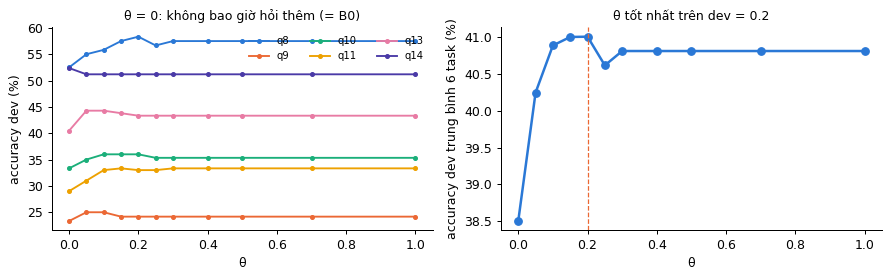

θ chọn: 0.2 | tỷ lệ mẫu kích hoạt vòng lặp: 69.0 %


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for t, c in zip(TASK_IDS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]):
    d = sweep[sweep.task == t]
    axes[0].plot(d.theta.clip(upper=1), 100 * d.accuracy, marker="o", ms=3, lw=1.5, color=c, label=t)
axes[0].set_xlabel("θ"); axes[0].set_ylabel("accuracy dev (%)"); axes[0].legend(frameon=False, ncol=3, fontsize=8)
axes[0].set_title("θ = 0: không bao giờ hỏi thêm (= B0)", fontsize=10)
axes[1].plot(np.minimum(mean.index, 1), 100 * mean.accuracy, marker="o", color=BLUE, lw=2, label="accuracy tb")
axes[1].set_xlabel("θ"); axes[1].set_ylabel("accuracy dev trung bình 6 task (%)")
axes[1].axvline(min(best, 1), color=ORANGE, ls="--", lw=1)
axes[1].set_title(f"θ tốt nhất trên dev = {best}", fontsize=10)
plt.tight_layout(); plt.show()
print("θ chọn:", best, "| tỷ lệ mẫu kích hoạt vòng lặp:", round(100 * mean.loc[best, "kích hoạt"], 1), "%")

In [11]:
# hanh dong nao duoc chon, va lan chon do co giup khong
rows = []
for t, recs in trace.items():
    for r in recs:
        prev_ok = None
        for st in r["steps"]:
            ok = max(st["dist"], key=st["dist"].get) == r["gold"]
            if prev_ok is not None:
                rows[-1].update({"sau": ok})
            if "action" in st:
                rows.append({"task": t, "hành động": st["action"], "lý do": st["reason"], "trước": ok})
            prev_ok = ok
acts = pd.DataFrame(rows)
acts["sửa đúng"] = ~acts["trước"] & acts["sau"]
acts["làm sai"] = acts["trước"] & ~acts["sau"]
acts.groupby("hành động").agg(số_lần=("task", "size"), sửa_đúng=("sửa đúng", "sum"), làm_sai=("làm sai", "sum"))

,số_lần,sửa_đúng,làm_sai
hành động,,,
more_frames,1134,51,30
pairwise,1088,26,37
reorder,1134,70,49


In [12]:
# mot vi du day du: cac buoc ma agent da di
ex = next(r for r in trace["q8"] if len(r["steps"]) >= 3 and r["pred"] == r["gold"] and r["steps"][0]["dist"] and
          max(r["steps"][0]["dist"], key=r["steps"][0]["dist"].get) != r["gold"])
s = next(x for x in load_clean("q8") if x.index == ex["index"])
print(s.question); print({k: s.option_texts[k] for k in s.option_keys}, "| đáp án", s.gold_key, "\n")
for i, st in enumerate(ex["steps"]):
    d = {k: round(v, 2) for k, v in st["dist"].items()}
    print(f"bước {i}: {d}  độ tin {st['confidence']:.2f}")
    if "action" in st:
        print(f"   -> {st['action']}: {st['reason']}")

How does the camera move in the video?
{'O1': 'From Close-up corner to Inside the goal.', 'O2': 'From Main behind the goal to Close-up player or field referee.', 'O3': 'From Close-up side staff to Main camera center.', 'O4': 'From Inside the goal to Public.'} | đáp án O2 

bước 0: {'O1': 0.44, 'O2': 0.43, 'O3': 0.07, 'O4': 0.05}  độ tin 0.01
   -> pairwise: phan van giua O1 va O2 -> hoi rieng 2 phuong an
bước 1: {'O1': 0.26, 'O2': 0.61, 'O3': 0.07, 'O4': 0.05}  độ tin 0.35
   -> reorder: cac nguon chon khac nhau -> hoi lai theo cach khac
bước 2: {'O1': 0.21, 'O2': 0.65, 'O3': 0.06, 'O4': 0.08}  độ tin 0.43
   -> more_frames: phan van dan trai -> lay them thong tin
bước 3: {'O1': 0.25, 'O2': 0.61, 'O3': 0.06, 'O4': 0.07}  độ tin 0.36


## 3. B0 và B0 + vòng lặp (test)

In [13]:
loop = {t: load_predictions("b0_loop", t, "test") for t in TASK_IDS}
rows = []
for t in TASK_IDS:
    if not loop[t]:
        continue
    common = {r["index"] for r in loop[t]}
    a = [r for r in b0[t] if r["index"] in common]
    m = mcnemar(a, loop[t])
    rows.append({"task": t, "n": m["n"], "B0": 100 * accuracy(a), "B0 + loop": 100 * accuracy(loop[t]),
                 "b (loop sửa đúng)": m["b"], "c (loop làm sai)": m["c"], "p": m["p_value"],
                 "kích hoạt (%)": 100 * np.mean([len(r["steps"]) > 1 for r in loop[t]])})
cmp = pd.DataFrame(rows).set_index("task").round(3)
cmp

,n,B0,B0 + loop,b (loop sửa đúng),c (loop làm sai),p,kích hoạt (%)
task,,,,,,,
q8,280,45.357,52.500,32,12,0.004,66.429
q9,280,27.500,25.000,5,12,0.143,72.500
q10,700,36.143,37.429,35,26,0.306,64.143
q11,700,31.286,37.857,74,28,0.000,73.286
q13,490,45.918,46.122,36,35,1.000,75.306
q14,192,56.771,57.292,8,7,1.000,61.458
